# BERT + LoRA
**AIML339 Email Thread Triage**

`notebooks/bc3_bert_lora.ipynb` trained the classifier once (seed 42). This notebook repeats
**exactly the same configuration** with `N_RUNS` different random seeds, so that the classifier can be
reported as mean ± standard deviation instead of a single run.

What changes between runs: only the random seed, which controls the initialisation of the
classification head and the LoRA matrices, LoRA dropout, and the order of the training batches.
What stays fixed: data, thread-level split, hyperparameters, threshold and checkpoint-selection rule.

Outputs (written to `/content/results/`, downloaded as a zip at the end):
- `bc3_bert_lora_seed_runs.csv` — one row per seed: test metrics, per-label F1, best epoch, validation F1, training time, parameters.
- `bc3_bert_lora_seed_curves.csv` — per-epoch train loss, validation loss and validation micro F1 for every seed.
- `bc3_bert_lora_seed_predictions.csv` — test predictions of every seed (for paired statistical tests).

**Run on Google Colab with a GPU runtime** (Runtime > Change runtime type > T4 GPU), then *Runtime > Run all*.
The loop is resume-safe: if the session disconnects, run all again and finished seeds are skipped
(as long as `/content/results/` still exists).

## 0. Install dependencies

If you already ran the notebook in this session and got a torchao ImportError, use *Runtime > Restart session* after this cell and then *Run all* again.

In [1]:
!pip install -q transformers peft accelerate
!pip install -q -U torchao   # PEFT requires a recent torchao (same as bc3_bert_lora.ipynb)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 66.7 MB/s eta 0:00:00


## 1. Configuration

Identical to `bc3_bert_lora.ipynb`. The seeds are fixed in advance (0 to `N_RUNS - 1`) and never derived from the clock.
The data is downloaded from the public repository, so no manual upload is needed.

In [2]:
import os, time, random, copy
import numpy as np
import pandas as pd
import torch

# --- Data ----------------------------------------------------------------------
DATA_URL    = "https://raw.githubusercontent.com/alfredoesti/aiml339-email-thread-triage/main/data/bc3_emails_labeled.csv"
RESULTS_DIR = "/content/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
RUNS_CSV  = os.path.join(RESULTS_DIR, "bc3_bert_lora_seed_runs.csv")
CURVE_CSV = os.path.join(RESULTS_DIR, "bc3_bert_lora_seed_curves.csv")
PRED_CSV  = os.path.join(RESULTS_DIR, "bc3_bert_lora_seed_predictions.csv")

# --- Model and labels (same as bc3_bert_lora.ipynb) -----------------------------
MODEL_NAME  = "bert-base-uncased"
LABEL_NAMES = ["Request", "Propose", "Commit", "Meeting", "Subjective", "Informative"]
LABEL_COLS  = [f"label_{l}" for l in LABEL_NAMES]
NUM_LABELS  = len(LABEL_NAMES)

# --- Hyperparameters (same as bc3_bert_lora.ipynb) ------------------------------
MAX_LEN      = 256
BATCH_SIZE   = 8
EPOCHS       = 5
LR           = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.10
MAX_GRAD_NORM = 1.0
THRESHOLD    = 0.5
LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.1
LORA_TARGETS = ["query", "key", "value", "dense"]

# --- Repeated runs ----------------------------------------------------------------
N_RUNS = 30                       # reduce (e.g. 10) if Colab time is limited
SEEDS  = list(range(N_RUNS))      # fixed seeds: 0, 1, ..., N_RUNS-1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"Device: {device} ({GPU_NAME})")

df = pd.read_csv(DATA_URL)
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "val"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)
print(f"Train: {len(train_df)} emails | Val: {len(val_df)} | Test: {len(test_df)}")

Device: cuda (Tesla T4)
Train: 187 emails | Val: 37 | Test: 37


## 2. Tokenization (done once)

The tokenizer is deterministic, so all emails are tokenized once and shared by every run.

In [3]:
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(frame):
    enc = tokenizer(frame["body"].fillna("").tolist(), max_length=MAX_LEN,
                    padding="max_length", truncation=True, return_tensors="pt")
    labels = torch.tensor(frame[LABEL_COLS].values.astype(np.float32))
    return TensorDataset(enc["input_ids"], enc["attention_mask"], labels)

train_ds, val_ds, test_ds = encode(train_df), encode(val_df), encode(test_df)

# Class-weighted BCE: pos_weight computed on the training set only
y_train_np = train_df[LABEL_COLS].values
pos = y_train_np.sum(axis=0)
neg = len(y_train_np) - pos
POS_WEIGHT = torch.tensor(neg / np.maximum(pos, 1), dtype=torch.float32)
print("pos_weight:", dict(zip(LABEL_NAMES, POS_WEIGHT.numpy().round(2))))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

pos_weight: {'Request': np.float32(1.31), 'Propose': np.float32(2.22), 'Commit': np.float32(3.92), 'Meeting': np.float32(2.46), 'Subjective': np.float32(0.38), 'Informative': np.float32(7.5)}


## 3. One training run

`run_one(seed)` reproduces the training procedure of `bc3_bert_lora.ipynb`: BERT + LoRA, class-weighted BCE,
AdamW with linear warmup, gradient clipping, 5 epochs, and the checkpoint with the best validation micro F1 restored
before testing. Training time is measured from the first to the last training iteration and excludes validation and test.

In [4]:
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model, TaskType
from torch.optim import AdamW
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def predict(model, loader):
    model.eval()
    preds, labels, total_loss = [], [], 0.0
    criterion = torch.nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(device))
    with torch.no_grad():
        for ids, mask, y in loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            logits = model(input_ids=ids, attention_mask=mask).logits
            total_loss += criterion(logits, y).item()
            preds.append((torch.sigmoid(logits) >= THRESHOLD).int().cpu().numpy())
            labels.append(y.cpu().numpy())
    return np.vstack(preds), np.vstack(labels), total_loss / len(loader)

def run_one(seed):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

    base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS, problem_type="multi_label_classification")
    lora_cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=LORA_R, lora_alpha=LORA_ALPHA,
                          lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGETS, bias="none")
    model = get_peft_model(base, lora_cfg).to(device)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total     = sum(p.numel() for p in model.parameters())

    criterion = torch.nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(device))
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * WARMUP_FRAC), total_steps)

    best_f1, best_epoch, best_state, curve, train_time = -1.0, None, None, [], 0.0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.perf_counter()
        for ids, mask, y in train_loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(input_ids=ids, attention_mask=mask).logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
            optimizer.step()
            scheduler.step()
            running += loss.item()
        if torch.cuda.is_available(): torch.cuda.synchronize()
        train_time += time.perf_counter() - t0

        vp, vy, vloss = predict(model, val_loader)
        vf1 = f1_score(vy, vp, average="micro", zero_division=0)
        curve.append({"seed": seed, "epoch": epoch, "train_loss": running / len(train_loader),
                      "val_loss": vloss, "val_micro_f1": vf1})
        if vf1 > best_f1:
            best_f1, best_epoch = vf1, epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    tp, ty, _ = predict(model, test_loader)
    per_label = f1_score(ty, tp, average=None, zero_division=0)
    row = {
        "seed": seed, "best_epoch": best_epoch, "val_micro_f1": best_f1,
        "test_micro_f1": f1_score(ty, tp, average="micro", zero_division=0),
        "test_macro_f1": f1_score(ty, tp, average="macro", zero_division=0),
        "test_micro_precision": precision_score(ty, tp, average="micro", zero_division=0),
        "test_micro_recall": recall_score(ty, tp, average="micro", zero_division=0),
        "test_hamming_loss": hamming_loss(ty, tp),
        **{f"test_f1_{n}": v for n, v in zip(LABEL_NAMES, per_label)},
        "train_time_sec": train_time, "trainable_params": n_trainable, "total_params": n_total,
        "gpu": GPU_NAME,
    }
    preds = test_df[["listno", "email_num"]].copy()
    preds.insert(0, "seed", seed)
    for i, n in enumerate(LABEL_NAMES):
        preds[f"pred_{n}"] = tp[:, i]
        preds[f"true_{n}"] = ty[:, i]

    del model, base, optimizer, best_state
    torch.cuda.empty_cache()
    return row, pd.DataFrame(curve), preds

## 4. Run all seeds

Each finished seed is appended to the three CSVs immediately, so progress survives a disconnection.

In [5]:
def append(path, frame):
    frame.to_csv(path, mode="a", header=not os.path.exists(path), index=False)

done = set(pd.read_csv(RUNS_CSV)["seed"]) if os.path.exists(RUNS_CSV) else set()
print(f"Already done: {sorted(done)}")

for seed in SEEDS:
    if seed in done:
        continue
    t = time.time()
    row, curve, preds = run_one(seed)
    append(RUNS_CSV, pd.DataFrame([row]))
    append(CURVE_CSV, curve)
    append(PRED_CSV, preds)
    print(f"seed {seed:2d} | best epoch {row['best_epoch']} | val micro F1 {row['val_micro_f1']:.3f} | "
          f"test micro F1 {row['test_micro_f1']:.3f} | macro F1 {row['test_macro_f1']:.3f} | "
          f"train {row['train_time_sec']:.0f}s | total {time.time() - t:.0f}s")

Already done: []


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


seed 28 | best epoch 4 | val micro F1 0.673 | test micro F1 0.620 | macro F1 0.512 | train 41s | total 47s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


seed 29 | best epoch 4 | val micro F1 0.636 | test micro F1 0.562 | macro F1 0.432 | train 41s | total 46s


## 5. Summary over seeds

In [6]:
runs = pd.read_csv(RUNS_CSV).sort_values("seed")
cols = ["test_micro_f1", "test_macro_f1", "test_micro_precision", "test_micro_recall", "test_hamming_loss",
        "val_micro_f1", "best_epoch", "train_time_sec"] + [f"test_f1_{n}" for n in LABEL_NAMES]
summary = runs[cols].agg(["mean", "std", "min", "max"]).T.round(3)
print(f"Runs: {len(runs)} (seeds {runs['seed'].min()}-{runs['seed'].max()}), GPU: {runs['gpu'].iloc[0]}")
print(f"Trainable parameters: {runs['trainable_params'].iloc[0]:,} of {runs['total_params'].iloc[0]:,}")
print(summary.to_string())

Runs: 30 (seeds 0-29), GPU: Tesla T4
Trainable parameters: 1,344,006 of 110,830,860
                        mean    std     min     max
test_micro_f1          0.596  0.030   0.532   0.661
test_macro_f1          0.483  0.029   0.432   0.549
test_micro_precision   0.509  0.032   0.465   0.588
test_micro_recall      0.725  0.063   0.602   0.818
test_hamming_loss      0.389  0.035   0.320   0.446
val_micro_f1           0.665  0.034   0.567   0.712
best_epoch             4.100  1.185   1.000   5.000
train_time_sec        40.814  0.324  40.245  42.243
test_f1_Request        0.551  0.109   0.200   0.667
test_f1_Propose        0.528  0.035   0.421   0.579
test_f1_Commit         0.454  0.148   0.111   0.606
test_f1_Meeting        0.559  0.066   0.385   0.688
test_f1_Subjective     0.806  0.055   0.654   0.889
test_f1_Informative    0.000  0.000   0.000   0.000


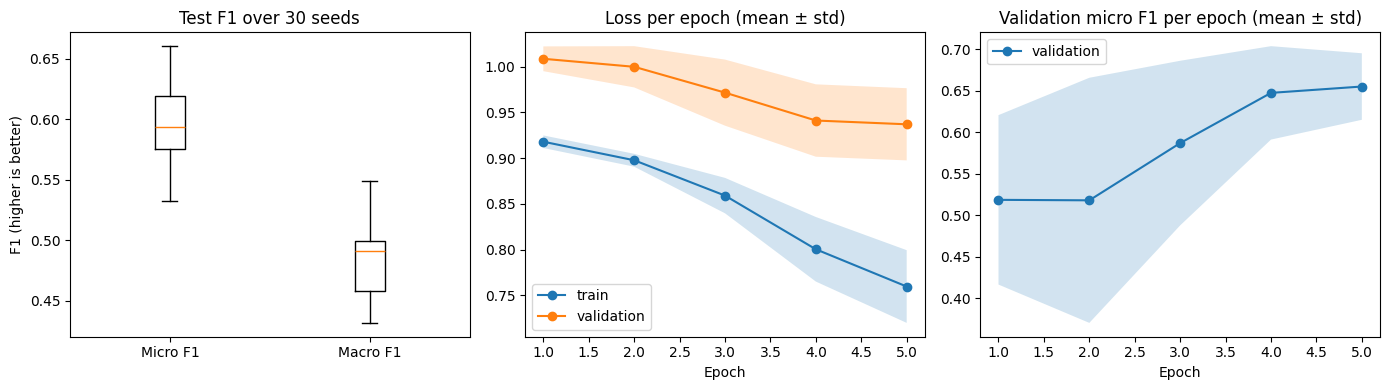

In [7]:
import matplotlib.pyplot as plt

curves = pd.read_csv(CURVE_CSV)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].boxplot([runs["test_micro_f1"], runs["test_macro_f1"]])
axes[0].set_xticks([1, 2], ["Micro F1", "Macro F1"])
axes[0].set_title(f"Test F1 over {len(runs)} seeds")
axes[0].set_ylabel("F1 (higher is better)")

for metric, ax, title in [("train_loss", axes[1], "Loss per epoch (mean ± std)"),
                          ("val_micro_f1", axes[2], "Validation micro F1 per epoch (mean ± std)")]:
    g = curves.groupby("epoch")
    for m, label in ([("train_loss", "train"), ("val_loss", "validation")] if metric == "train_loss"
                     else [("val_micro_f1", "validation")]):
        mean, std = g[m].mean(), g[m].std()
        ax.plot(mean.index, mean.values, marker="o", label=label)
        ax.fill_between(mean.index, mean - std, mean + std, alpha=0.2)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "bc3_bert_lora_seed_runs.png"), dpi=150)
plt.show()

## 6. Download the results

Downloads `results.zip` with the three CSVs and the figure. Send it together with this executed notebook
(*File > Download > Download .ipynb*).

In [8]:
import shutil
shutil.make_archive("/content/results", "zip", RESULTS_DIR)
try:
    from google.colab import files
    files.download("/content/results.zip")
except ImportError:
    print("Not running on Colab: results are in", RESULTS_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>